# Pipeline de diseño de conexiones a momento atornilladas — paso a paso (v3)

Recorre todo el proceso reutilizando el mismo código de `config.py`, `lookups.py`,
`geometry.py`, `dataset.py`, `model.py`, `losses.py`, `training.py`, `postprocess.py` y
`evaluation.py` (no hay lógica duplicada entre el notebook y `train.py`).

**Novedad v3**: `p1..p12` deja de ser un target. Cada `p_k` mezclaba roles distintos según
la topología (a veces era un `D`, a veces el `I-C`, a veces un hueco de cantonera), lo que
lo volvía multimodal para una regresión. Se sustituye por variables con **significado fijo**
en todas las muestras, calcadas del plano:

- `E-S` : hueco fila 1 -> fila 2 (extensión superior)
- `D_1..D_5` : huecos interiores dentro del tramo de la viga
- `I-C` : hueco que contiene el ala inferior de la viga
- `C_1..C_5` : **nuevo** — huecos interiores dentro de la zona de la cantonera (antes se
  perdían: solo se guardaba el último hueco como `E-C`)
- `E-C` : último hueco (extensión inferior)

No existe columna `C_i` real en `train/test.parquet` (es un concepto nuevo), así que estas
variables se derivan de `p1..p12 + e + d + BEAM_d_mm` con `geometry.gaps_from_p` — es la
misma información, reparametrizada. `geometry.check_reversibility` comprueba que reconstruir
`p1..p12` desde estas variables reproduce el `p` real (si no, se pierde información).

Todas pasan a tratarse como **regresión con máscara**, igual que los rigidizadores (Huber +
presencia, normalizado por columna): al tener ya un rol fijo no hace falta la clasificación
sobre rejilla de la versión anterior.

**Limitaciones a vigilar** (ver secciones 3 y 7):
- `D_1..D_5` y `C_1..C_5` truncan a 5 huecos cada uno; con conexiones muy altas (9+ pasos)
  se puede perder información — `verificar_reversibilidad` lo mide.
- `C_i` puede sufrir la misma escasez de ejemplos que antes tenían `p8..p12`: solo existen
  en conexiones con cantonera Y con más de un hueco tras el ala inferior.

In [1]:
import sys, pandas as pd, numpy as np, torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from pathlib import Path

from config import (
    CATEGORICAL_FEATURES, NUMERIC_FEATURES, REGRESSION_ALWAYS,
    P_COLUMNS, GEOM_COLUMNS, STIFFENER_COLUMNS, MASKED_COLUMNS, CATALOGO_BOLT,
)
from lookups import build_profile_lookup_from_tekla_csvs, check_profile_coverage, build_training_features
from geometry import gaps_from_p, check_reversibility
from dataset import Preprocessor, ConnectionDataset, add_geometry_targets
from model import ConnectionDesignNet
from losses import ConnectionDesignLoss
from training import fit, forward_numpy, predict_loader, outputs_to_design
from evaluation import (preparar_para_evaluar, evaluar_predicciones, evaluar_estructura,
                        error_geom_por_canto, diagnostico_geometria, verificar_reversibilidad)

torch.manual_seed(42); np.random.seed(42)

In [2]:
DATA_PATH = Path().cwd() / "data"

## 1. Carga de datos y catálogos Tekla

In [3]:
train_raw = pd.read_parquet(DATA_PATH / "train.parquet")
test_raw = pd.read_parquet(DATA_PATH / "test.parquet")
print("train:", train_raw.shape, "| test:", test_raw.shape)
train_raw.head()

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\jabal\\OtrosProyectos\\proyecto_uniones\\V2\\model\\data\\train.parquet'

In [ ]:
def prepare_raw_equivalent(df, rare_threshold=20):
    df = df.rename(columns={"AceroEstructural": "grado_acero", "EstandarTornillos": "clase_tornillo"})
    counts = df["DrawingCode"].value_counts()
    rare = counts[counts < rare_threshold].index
    if len(rare) > 0:
        df["DrawingCode"] = df["DrawingCode"].where(~df["DrawingCode"].isin(rare), "OTHER")
    return df

train_full = prepare_raw_equivalent(train_raw)
test_full = prepare_raw_equivalent(test_raw)
print(train_full["DrawingCode"].value_counts())

DrawingCode
MLE      2258
MHE      1450
OTHER      35
MOE        34
Name: count, dtype: int64


In [ ]:
profile_lookup = build_profile_lookup_from_tekla_csvs("tekla_eu.csv", "tekla_cad.csv", "tekla_faltante.csv")
print(f"Perfiles en catálogo Tekla: {len(profile_lookup)}")
profile_lookup.head()

Perfiles en catálogo Tekla: 407


,type,d_mm,bf_mm,tw_mm,tf_mm,r1_mm,wely_mm,w_kgm
profile,,,,,,,,
HEA100,HE,96.0,100.0,5.0,8.0,12.0,72.8,16.700001
HEA1000,HE,990.0,300.0,16.5,31.0,30.0,11190.0,272.000000
HEA120,HE,114.0,120.0,5.0,8.0,12.0,106.3,19.900000
HEA140,HE,133.0,140.0,5.5,8.5,12.0,155.4,24.700001
HEA160,HE,152.0,160.0,6.0,9.0,15.0,220.1,30.400000


In [ ]:
needed = set(train_full["BEAM"]) | set(train_full["COLUMN"]) | set(test_full["BEAM"]) | set(test_full["COLUMN"])
missing = check_profile_coverage(needed, profile_lookup)
print(f"Perfiles no cubiertos: {len(missing)} de {len(needed)}")
assert len(missing) == 0, f"Faltan perfiles: {missing}"

Perfiles no cubiertos: 0 de 103


## 2. Split y verificación de reversibilidad (p1..p12 <-> geometría con nombre)

In [ ]:
train_df, val_df = train_test_split(train_full, test_size=0.15, random_state=42)
test_df = test_full
print(f"train={len(train_df)} val={len(val_df)} test={len(test_df)}")

train=3210 val=567 test=945


In [ ]:
# ¿La descomposición E-S/D_i/I-C/C_i/E-C reproduce EXACTAMENTE el p1..p12 real?
# Si no coincide en el 100%, o hay más de MAX_D+MAX_C huecos en algún tramo (se trunca)
# o el ala inferior cae fuera del rango de filas modeladas (input inconsistente).
print("--- train ---"); r_tr = verificar_reversibilidad(train_df)
print("--- test  ---"); r_te = verificar_reversibilidad(test_df)

--- train ---
Reconstrucción p exacta: 100.0% de las filas (0 de 3210 no coinciden)
--- test  ---
Reconstrucción p exacta: 100.0% de las filas (0 de 945 no coinciden)


In [ ]:
# nº de pasos de las filas donde la reconstrucción falla: si se concentra en valores altos,
# es el límite MAX_D/MAX_C (config.py); si aparece en valores bajos, revisar geometry.py.
n_pasos = (train_df[P_COLUMNS].fillna(0) > 0).sum(axis=1)
print(n_pasos.value_counts().sort_index())

2      28
3     918
4     893
5     627
6     421
7     167
8      88
9      27
10     34
12      7
Name: count, dtype: int64


## 3. Construcción de features y de la geometría con nombre

In [ ]:
for c in NUMERIC_FEATURES:
    assert c in train_df.columns, f"falta {c}"
print("Features numéricas OK:", NUMERIC_FEATURES)

Features numéricas OK: ['BEAM_d_mm', 'BEAM_bf_mm', 'BEAM_tw_mm', 'BEAM_tf_mm', 'BEAM_r1_mm', 'BEAM_wely_mm', 'BEAM_w_kgm', 'COLUMN_d_mm', 'COLUMN_bf_mm', 'COLUMN_tw_mm', 'COLUMN_tf_mm', 'COLUMN_r1_mm', 'COLUMN_wely_mm', 'COLUMN_w_kgm', 'fy_acero_mpa', 'fu_acero_mpa', 'fy_tornillo_mpa', 'fu_tornillo_mpa', 'fv_tornillo_mpa', 'Capacity_Moment', 'Capacity_Shear', 'Capacity_Axial']


In [11]:
train_df, val_df, test_df = (add_geometry_targets(d) for d in (train_df, val_df, test_df))
train_df[GEOM_COLUMNS].describe().T

,count,mean,std,min,25%,50%,75%,max
E-S,3210.0,116.233364,22.869924,73.5,100.0,111.5,135.0,170.0
D_1,3177.0,102.151967,35.409478,45.0,75.0,95.0,125.0,300.8
D_2,1301.0,135.694850,47.935677,50.0,100.0,130.0,160.0,295.0
D_3,224.0,150.133929,32.948933,85.0,135.0,140.0,170.0,240.0
D_4,58.0,132.155172,17.773232,85.0,125.0,140.0,147.5,150.0
D_5,7.0,140.000000,0.000000,140.0,140.0,140.0,140.0,140.0
I-C,3210.0,139.031807,41.429519,45.0,110.0,133.5,155.0,290.0
C_1,1302.0,102.649641,46.510811,45.0,70.0,95.0,120.0,295.0
C_2,325.0,105.196923,28.759614,45.0,85.0,113.0,130.0,175.0
C_3,68.0,112.132353,25.499725,75.0,85.0,110.0,130.0,150.0


In [12]:
# ¿Se cumplen Lp = 2e + Σp y Σp = h_viga + 2d? (sobre p1..p12 crudo; informativo, no se fuerza)
diagnostico_geometria(train_df)
print("\nd múltiplo de 5 en train:", round((train_df["d"] % 5 == 0).mean(), 3))

Lp - (2e + Σp)      :  78.7% de filas dentro de ±1 mm | mediana=0.0
Σp - (h_viga + 2d)  :  42.6% de filas dentro de ±1 mm | mediana=134.0

d múltiplo de 5 en train: 0.873


## 4. Dataset y DataLoader

In [13]:
pre = Preprocessor().fit(train_df)
print("Cardinalidades categóricas:", pre.cat_cardinalities)
print("Nº clases DrawingCode:", pre.n_drawing_codes, "->", list(pre.drawing_code_encoder.classes_))
print("\n% de muestras activas por columna enmascarada (geometría + rigidizadores):")
print(pd.Series(pre.masked_active_frac * 100, index=MASKED_COLUMNS).round(1))

Cardinalidades categóricas: [3, 4, 2, 3]
Nº clases DrawingCode: 4 -> ['MHE', 'MLE', 'MOE', 'OTHER']

% de muestras activas por columna enmascarada (geometría + rigidizadores):
E-S    100.0
D_1     99.0
D_2     40.5
D_3      7.0
D_4      1.8
D_5      0.2
I-C    100.0
C_1     40.6
C_2     10.1
C_3      2.1
C_4      0.2
C_5      0.0
E-C     52.8
tws      2.4
ts      95.9
tbs     54.0
tst     51.2
dtype: float64


In [14]:
train_ds = ConnectionDataset(train_df, pre)
val_ds = ConnectionDataset(val_df, pre)
test_ds = ConnectionDataset(test_df, pre)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=128, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)

batch = next(iter(train_loader))
for k, v in batch.items():
    print(f"{k:<18} {tuple(v.shape)} {v.dtype}")

x_cat              (64, 4) torch.int64
x_num              (64, 22) torch.float32
drawing_code_idx   (64,) torch.int64
bolt_idx           (64,) torch.int64
slip_critical      (64,) torch.float32
reg_always         (64, 6) torch.float32
masked_value       (64, 17) torch.float32
masked_mask        (64, 17) torch.float32


In [15]:
train_df.columns

Index(['Capacity_Moment', 'Capacity_Shear', 'Capacity_Axial', 'g', 'tws', 'Bp',
       'Lp', 'tp', 'e', 'd', 'p1', 'p2', 'p3', 'p4', 'p5', 'p6', 'p7', 'p8',
       'p9', 'p10', 'p11', 'p12', 'ts', 'tbs', 'tst', 'Hole', 'BEAM', 'COLUMN',
       'DrawingCode', 'Bolt', 'SlipCritical', 'grado_acero', 'clase_tornillo',
       'Source', 'standard', 'BEAM_type', 'BEAM_d_mm', 'BEAM_bf_mm',
       'BEAM_tw_mm', 'BEAM_tf_mm', 'BEAM_r1_mm', 'BEAM_wely_mm', 'BEAM_w_kgm',
       'COLUMN_type', 'COLUMN_d_mm', 'COLUMN_bf_mm', 'COLUMN_tw_mm',
       'COLUMN_tf_mm', 'COLUMN_r1_mm', 'COLUMN_wely_mm', 'COLUMN_w_kgm',
       'fy_acero_mpa', 'fu_acero_mpa', 'fy_tornillo_mpa', 'fu_tornillo_mpa',
       'fv_tornillo_mpa', 'D_1', 'D_2', 'D_3', 'D_4', 'D_5', 'E-C', 'E-S',
       'I-C', 'num_filas_tornillos', 'tiene_cantonera', 'C_1', 'C_2', 'C_3',
       'C_4', 'C_5'],
      dtype='str')

## 5. Modelo

In [32]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

model = ConnectionDesignNet(
    cat_cardinalities=pre.cat_cardinalities,
    num_continuous=len(pre.num_scaler.mean_),
    n_drawing_codes=pre.n_drawing_codes,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros entrenables: {n_params:,}")
model

device: cpu
Parámetros entrenables: 328,970


ConnectionDesignNet(
  (embeddings): ModuleList(
    (0): Embedding(3, 2)
    (1): Embedding(4, 2)
    (2): Embedding(2, 1)
    (3): Embedding(3, 2)
  )
  (input_layer): Sequential(
    (0): Linear(in_features=29, out_features=192, bias=True)
    (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (blocks): ModuleList(
    (0-2): 3 x ResNetBlock(
      (fc1): Linear(in_features=192, out_features=192, bias=True)
      (bn1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (fc2): Linear(in_features=192, out_features=192, bias=True)
      (bn2): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (act): ReLU()
    )
  )
  (head_drawing_code): Sequential(
    (0): Linear(in_features=192, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=4, bias=

In [33]:
out = forward_numpy(model, batch["x_cat"], batch["x_num"], device)
for k, v in out.items():
    print(f"{k:<22} {tuple(v.shape)}")

drawing_code_logits    (64, 4)
bolt_logits            (64, 7)
slip_critical_logit    (64,)
reg_always             (64, 6)
masked_value           (64, 17)
masked_presence_logit  (64, 17)


## 6. Entrenamiento

In [34]:
criterion = ConnectionDesignLoss()
EPOCHS = 200  # subir a 150+ para el entrenamiento final
history = fit(model, train_loader, val_loader, criterion, device, epochs=EPOCHS, lr=0.005)

epoch 001/200 | train=3.9827 | val=2.7096 | val masked_value=0.194 presence=0.277
epoch 020/200 | train=1.1105 | val=0.9981 | val masked_value=0.088 presence=0.060
epoch 040/200 | train=0.6853 | val=0.5848 | val masked_value=0.069 presence=0.034
epoch 060/200 | train=0.5314 | val=0.5079 | val masked_value=0.047 presence=0.029
epoch 080/200 | train=0.4124 | val=0.6066 | val masked_value=0.054 presence=0.031
epoch 100/200 | train=0.2969 | val=0.4377 | val masked_value=0.035 presence=0.027
epoch 120/200 | train=0.2652 | val=0.6019 | val masked_value=0.030 presence=0.035


KeyboardInterrupt: 

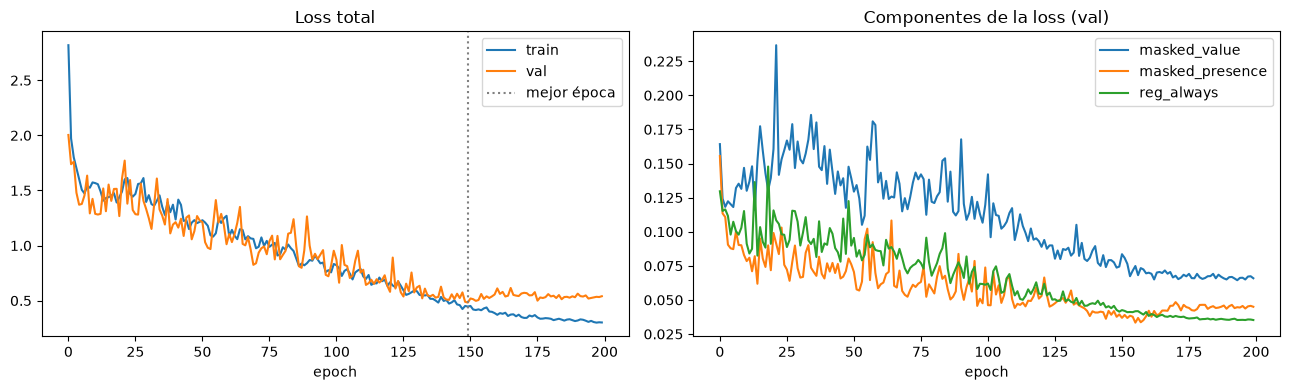

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history["train_loss"], label="train"); axes[0].plot(history["val_loss"], label="val")
axes[0].axvline(history["best_epoch"] - 1, color="gray", ls=":", label="mejor época")
axes[0].set_title("Loss total"); axes[0].set_xlabel("epoch"); axes[0].legend()
for k in ("masked_value", "masked_presence", "reg_always"):
    axes[1].plot([d[k] for d in history["val_parts"]], label=k)
axes[1].set_title("Componentes de la loss (val)"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Evaluación y métricas por variable (en test)

In [ ]:
outputs = predict_loader(model, test_loader, device)
full_design = outputs_to_design(outputs, pre, reconstruct_p=True)
full_design.head()

,g,e,d,Bp,Lp,tp,E-S,D_1,D_2,D_3,...,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12
0,140.0,50.0,52.041752,227.0,423.581909,20.0,100.0,85.0,0.0,0.0,...,105.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,115.0,40.0,41.753437,184.0,374.030670,15.0,90.0,70.0,0.0,0.0,...,95.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,125.0,40.0,48.307869,290.0,641.335754,25.0,115.0,105.0,105.0,0.0,...,105.0,120.0,80.0,130.0,0.0,0.0,0.0,0.0,0.0,0.0
3,115.0,60.0,47.854424,217.0,977.560669,25.0,100.0,45.0,235.0,0.0,...,235.0,305.0,70.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0
4,110.0,50.0,48.913273,198.0,603.265320,25.0,130.0,125.0,155.0,0.0,...,155.0,140.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
print("--- Clasificación ---")
for col in ("DrawingCode", "Bolt", "SlipCritical"):
    print(f"Accuracy {col:<13}:", (full_design[col].values == test_df[col].astype(str).values).mean().round(3))

df_real, df_pred = preparar_para_evaluar(test_df, full_design)
df_res = evaluar_predicciones(df_real, df_pred)

--- Clasificación ---
Accuracy DrawingCode  : 0.952
Accuracy Bolt         : 0.947
Accuracy SlipCritical : 0.99
                    EVALUACIÓN INTEGRAL DE PREDICCIONES Y TOLERANCIAS
Variable  N (Muestras)  MAE (mm)  RMSE (mm)  R2 Score  % Exacto (Catálogo)  % <= 5mm (Taller)  % <= 10mm (Taller)
       g           945      3.49       6.08     0.844                 52.0               85.9                96.1
       e           945      0.41       1.57     0.928                 92.7               99.2               100.0
       d           945      1.75       2.71     0.897                 25.4               94.4                98.9
      Bp           945      7.29      12.05     0.947                  6.8               57.2                77.1
      Lp           945     34.07      48.53     0.971                  1.7               12.8                22.2
      tp           945      0.79       2.12     0.858                 85.2               99.0                99.9
     E-S           94

In [ ]:
# num_filas_tornillos y tiene_cantonera, y presencia por columna de geometría
res_struct, conf = evaluar_estructura(test_df, full_design)

          ESTRUCTURA: num_filas_tornillos / tiene_cantonera
num_filas_tornillos exacto (%) :  91.6
num_filas_tornillos ±1 (%)     :  97.9
tiene_cantonera acierto (%)    :  96.7

Presencia por columna de geometría (acierto de existe/no existe):
E-S    100.0
D_1    100.0
D_2     97.5
D_3     99.0
D_4    100.0
D_5    100.0
I-C    100.0
C_1     97.0
C_2     98.9
C_3     99.8
C_4    100.0
C_5    100.0
E-C     96.7

num_filas_tornillos, real (filas) vs predicho (columnas):
pred  3    4    5    6    7   8   9   10  11  13
real                                            
3      5    0    0    0    0   0   0   0   0   0
4      0  224   14    4    2   0   0   0   0   0
5      0    3  243    2    3   0   0   0   0   0
6      0    4   14  162    9   2   0   0   0   0
7      0    1    3    6  129   3   0   0   0   0
8      0    0    0    1    1  53   2   0   0   0
9      0    0    0    0    0   3  25   0   0   0
10     0    0    0    0    0   0   2   9   0   0
11     0    0    0    0    0   0   0  

In [ ]:
tab_canto = error_geom_por_canto(test_df, full_design)

MAE (mm) de la geometría activa por canto de viga:
                    N  E-S   D_1   D_2   D_3  D_4  D_5   I-C   C_1   C_2  C_3  C_4  C_5  E-C
(113.999, 210.0]  252  4.4   7.5  14.2   NaN  NaN  NaN  10.2  18.1   NaN  NaN  NaN  NaN  6.5
(210.0, 290.0]    240  5.0  12.6  18.1   NaN  NaN  NaN  14.3   9.2   NaN  NaN  NaN  NaN  8.1
(290.0, 400.0]    244  6.6  20.2  17.1   NaN  NaN  NaN  18.2  12.1  21.4  NaN  NaN  NaN  9.3
(400.0, 890.0]    209  4.8  15.2  18.1  19.2  3.6  0.0  17.2  20.2   9.4  9.3  0.0  NaN  6.4


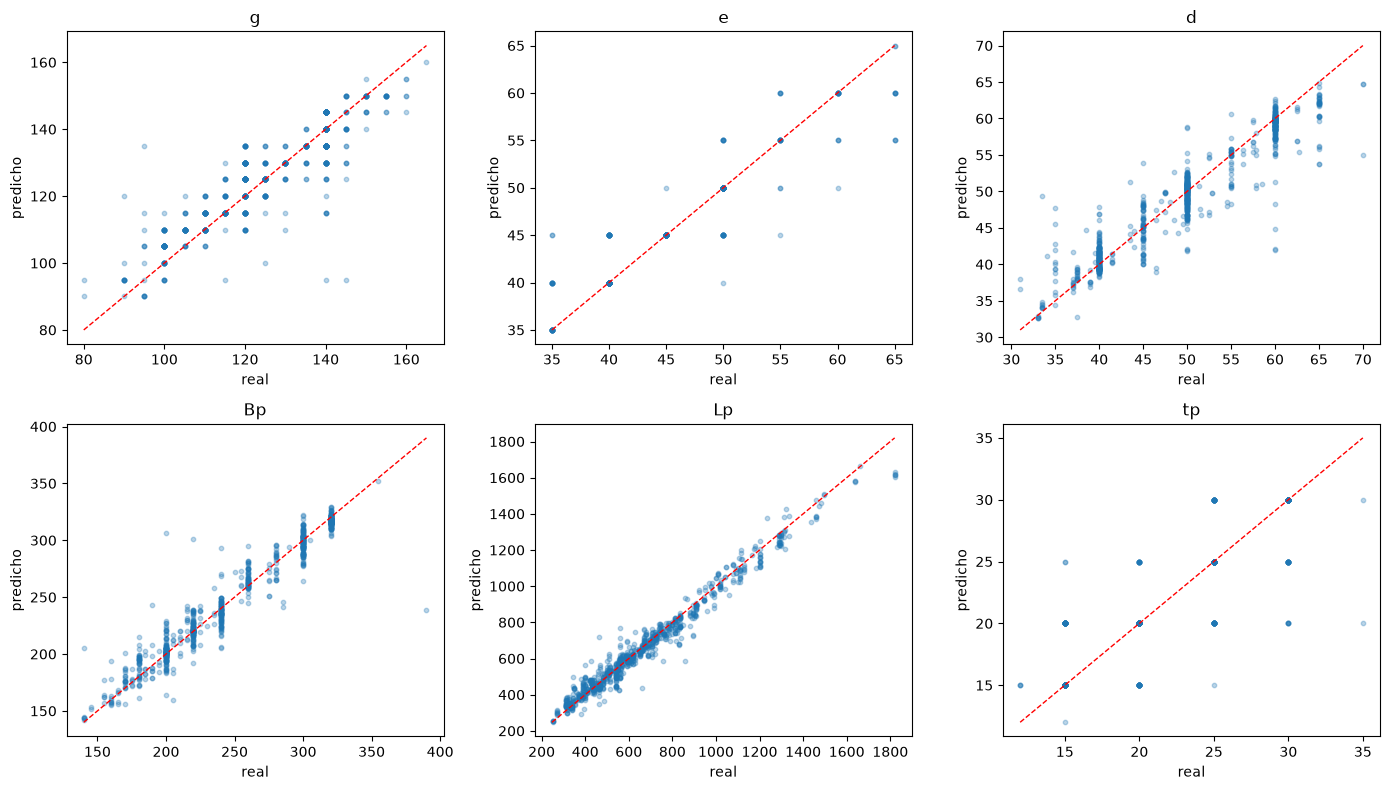

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, ["g", "e", "d", "Bp", "Lp", "tp"]):
    real, pred = test_df[col].values, full_design[col].values
    ax.scatter(real, pred, alpha=0.3, s=10)
    lims = [min(real.min(), pred.min()), max(real.max(), pred.max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_title(col); ax.set_xlabel("real"); ax.set_ylabel("predicho")
plt.tight_layout(); plt.show()

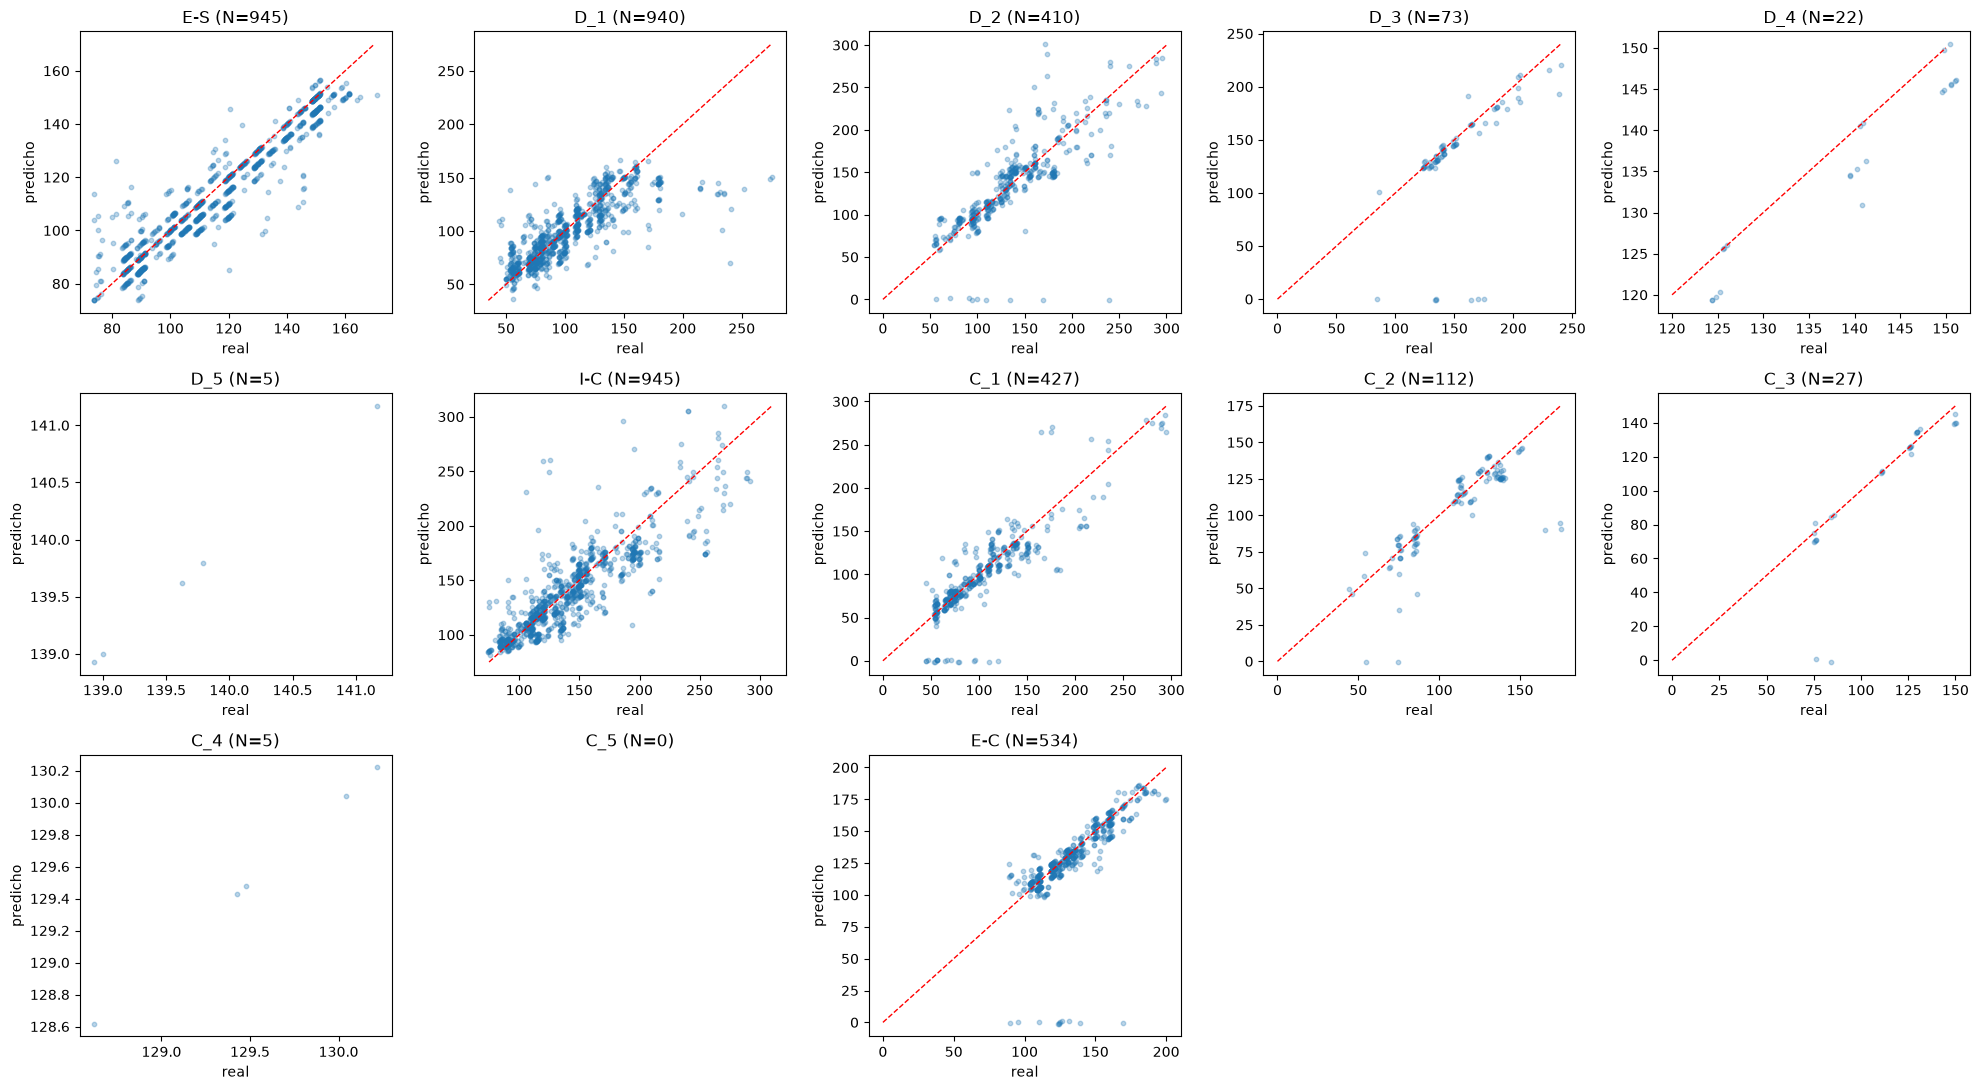

In [ ]:
# Real vs predicho para la geometría con nombre (donde existe en la realidad)
fig, axes = plt.subplots(3, 5, figsize=(20, 11))
for ax, col in zip(axes.flat, GEOM_COLUMNS):
    real = test_df[col].fillna(0).values; pred = full_design[col].values
    m = real > 0
    if m.sum() == 0:
        ax.set_title(f"{col} (N=0)"); ax.axis("off"); continue
    jitter = np.random.uniform(-1.5, 1.5, m.sum())
    ax.scatter(real[m] + jitter, pred[m] + jitter, alpha=0.3, s=10)
    lims = [min(real[m].min(), pred[m].min()), max(real[m].max(), pred[m].max())]
    ax.plot(lims, lims, "r--", linewidth=1)
    ax.set_title(f"{col} (N={m.sum()})"); ax.set_xlabel("real"); ax.set_ylabel("predicho")
for ax in axes.flat[len(GEOM_COLUMNS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 8. Inspección de casos concretos

In [ ]:
def compare_row(i):
    print(f"=== Muestra test #{i} — Viga: {test_df.iloc[i]['BEAM']} | Columna: {test_df.iloc[i]['COLUMN']} ===")
    cols = ["DrawingCode", "Bolt", "SlipCritical"] + REGRESSION_ALWAYS + GEOM_COLUMNS + STIFFENER_COLUMNS
    return pd.DataFrame({"real": test_df.iloc[i][cols], "predicho": full_design.iloc[i][cols]})

compare_row(100)

=== Muestra test #100 — Viga: HEB240 | Columna: HEA360 ===


,real,predicho
DrawingCode,MLE,MLE
Bolt,M24,M24
SlipCritical,NO,NO
g,125,125.0
e,40,40.0
d,45.0,47.349941
Bp,260,267.0
Lp,615,619.790527
tp,15,15.0
E-S,105.0,105.0


In [ ]:
# Peores 5 casos según el error acumulado en la geometría (para cazar errores gordos)
real = test_df[GEOM_COLUMNS].fillna(0).values
pred = full_design[GEOM_COLUMNS].values.astype(float)
err = np.abs(real - pred).sum(axis=1)
worst = np.argsort(err)[::-1][:5]
print("Índices (posición en test_df) con más error:", worst.tolist())
compare_row(worst[0])

Índices (posición en test_df) con más error: [594, 570, 633, 315, 407]
=== Muestra test #594 — Viga: IPE360 | Columna: HEB550 ===


,real,predicho
DrawingCode,MLE,MLE
Bolt,M20,M24
SlipCritical,NO,NO
g,120,130.0
e,35,45.0
d,35.0,47.729565
Bp,190,243.0
Lp,500,585.530823
tp,20,25.0
E-S,80.0,125.0


In [ ]:
# Comparación de p1..p12 reconstruidas (geometry.p_from_named) contra el p real:
# comprobación física de conjunto (además de mirar cada variable por separado).
p_pred = full_design[P_COLUMNS].values
p_real = test_df[P_COLUMNS].fillna(0).values
print("p exacta (todas las 12 iguales):", round(100 * np.mean(np.all(np.abs(p_pred - p_real) < 1e-6, axis=1)), 1), "%")
print("p, Σ|error| medio por fila:", round(np.abs(p_pred - p_real).sum(axis=1).mean(), 1), "mm")

p exacta (todas las 12 iguales): 0.1 %
p, Σ|error| medio por fila: 66.6 mm


## 9. Inferencia con un input "pobre" (tipo `fictional.csv`)

Flujo real de producción: solo `UNICODE, BEAM, COLUMN, Capacity_Moment, Capacity_Shear,
Capacity_Axial, grado_acero, clase_tornillo`, reconstruyendo el resto con
`lookups.build_training_features`. La salida ya trae `E-S, D_i, I-C, C_i, E-C` directamente
(no hace falta pasar por p1..p12); `p1..p12` se incluye solo por si algún sistema aguas
abajo todavía lo necesita (`reconstruct_p=True`).

In [ ]:
fictional = pd.read_csv(DATA_PATH / "fictional.csv")
print(fictional.shape)
fictional.head()

(2, 8)


,UNICODE,BEAM,COLUMN,Capacity_Moment,Capacity_Shear,Capacity_Axial,grado_acero,clase_tornillo
0,P0001,W610X195,W610X195,1746.5787,1009.940778,0,S355JR,A325M
1,P002,W690X152,W610X155,1598.1390,950.264568,0,S355JR,A325M


In [ ]:
infer_input = fictional

infer_features = build_training_features(infer_input, profile_lookup)
print(infer_features.shape)

(2, 29)


In [ ]:
x_cat, x_num = pre.transform_features(infer_features)
infer_out = forward_numpy(model, x_cat, x_num, device)
full_infer = outputs_to_design(infer_out, pre, reconstruct_p=True)
full_infer.insert(0, "BEAM", infer_features["BEAM"].values)
full_infer.insert(1, "COLUMN", infer_features["COLUMN"].values)
full_infer[["BEAM", "COLUMN", "Bolt", "num_filas_tornillos", "tiene_cantonera"] + GEOM_COLUMNS].head(10)

,BEAM,COLUMN,Bolt,num_filas_tornillos,tiene_cantonera,E-S,D_1,D_2,D_3,D_4,D_5,I-C,C_1,C_2,C_3,C_4,C_5,E-C
0,W610X195,W610X195,M36,9,True,120.0,85.0,195.0,195.0,0.0,0.0,110.0,260.0,90.0,0.0,0.0,0.0,135.0
1,W690X152,W610X155,M27,10,True,125.0,70.0,210.0,225.0,0.0,0.0,100.0,250.0,105.0,75.0,0.0,0.0,140.0
